## Task 3.1

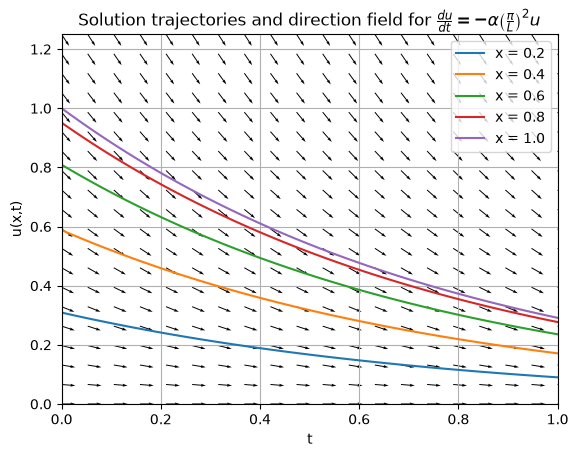

In [412]:
#source: https://www.geeksforgeeks.org/python/how-to-plot-a-simple-vector-field-in-matplotlib/
import numpy as np
import matplotlib.pyplot as plt

# function definitons
T=1.0
L=2.0
alpha=0.5
x0 = np.array([0.2, 0.4, 0.6, 0.8, 1.0])
t=np.linspace(0,T,100)

u=lambda x: np.sin((np.pi*x)/L)*np.exp(-alpha*(np.pi/L)**2*t)



# Meshgrid
tt, uu = np.meshgrid(np.linspace(0, T, 20), 
                   np.linspace(0, 1.25, 20))

# Vector function
k=-alpha*(np.pi/L)**2
slope=k*uu
normfactor = np.hypot(1, slope)

# Plotting differential equation as vector field
plt.quiver(tt, uu, 1/normfactor, k*uu/normfactor, color='k',width=0.002)


# Plotting the solution trajectories
for xi in x0:
    plt.plot(t,u(xi),label=f"x = {xi}") #, marker=">", markevery=20
plt.legend()
plt.xlabel("t")
plt.ylabel("u(x,t)")

plt.title("Solution trajectories and direction field for "r"$\frac{du}{dt}=-\alpha\left(\frac{\pi}{L}\right)^2u$"
)

# Setting x, y boundary limits
plt.xlim(0.0, T)    
plt.ylim(0.0, 1.25)

# Show plot with grid
plt.grid()
plt.show()

## Task 3.3

In [413]:
import torch
from torch import nn
import torch.nn.functional as F
import torch.optim as optim


num_hidden = 100
num_features = 2
num_output = 1

class Net(nn.Module):

    def __init__(self):
        super(Net, self).__init__()
        # Setting up variables, these variables are weights in your 
        # network that can be updated while running our graph.
        # Notice, to make a hidden layer, the weights need to have the 
        # following dimensionality:
        #   W[number_of_units_going_out, number_of_units_going_in]
        #   b[number_of_units_going_out]
        # in the example below we have 2 input units (num_features) and 2 output units (num_output)
        # so our weights become W[2, 2], b[2]
        # if we want to make a hidden layer with 100 units, we need to define the shape of the
        # first weight to W[100, 2], b[100] and the shape of the second weight to W[2, 100], b[2]
        
        # first layer
        self.W_1 = nn.Parameter(torch.randn(num_hidden, num_features)) 
        self.b_1 = nn.Parameter(torch.randn(num_hidden))
        
        # second layer (to be completed as an exercise)
        # NB when you create a second layer, remember that you also must change parts of the first layer
        self.W_2 = nn.Parameter(torch.randn(num_output, num_hidden))
        self.b_2 = nn.Parameter(torch.randn(num_output))
        
        
    def forward(self, x):
        # Setting up ops, these ops will define edges along our computational graph
        # The below ops will compute a logistic regression, 
        # but can be modified to compute a neural network
        x = F.linear(x, self.W_1, self.b_1)
        
        # second layer (to be completed as an exercise)
        x = F.tanh(x)
        # NB when you create a second layer, remember that you also must change parts of the first layer
        x = F.linear(x, self.W_2, self.b_2)
        return x 

net = Net()

In [414]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

def data_generator(n_samples=10, L=2, T=1, alpha=0.5):
    # Create covariates and response variable
    t = np.random.uniform(0, T, n_samples)
    x = np.random.uniform(0, L, n_samples)
    y = np.sin(np.pi*x/L)*np.exp(-alpha*(np.pi/L)**2*t)

    return t, x, y

data = data_generator(n_samples=10)




def data_generator_colloc(n_samples=200, L=2, T=1, alpha=0.5):
    # Create covariates and response variable
    t = np.random.uniform(0, T, n_samples)
    x = np.random.uniform(0, L, n_samples)
    y = np.sin(np.pi*x/L)*np.exp(-alpha*(np.pi/L)**2*t)

    return t, x, y

data_colloc = data_generator_colloc(n_samples=200)

def data_generator_bc(n_samples=10, T=1):
    t = np.random.uniform(0, T, n_samples)

    return t

data_bc = data_generator_bc(n_samples=10)

def data_generator_ic(n_samples=10, L=2):

    x = np.random.uniform(0, L, n_samples)


    return x

data_IC = data_generator_ic(n_samples=10)







In [415]:
L = 2
alpha = 0.5

def loss_heat(net, data_input, data_target, BC_input, IC_input, colloc_input, lambda_phys=1.0, lambda_IC=1.0, lambda_BC=1.0):

    colloc_input = colloc_input.detach().requires_grad_(True)
    data_out= net(data_input)
    colloc_out=net(colloc_input)

    L_data= nn.MSELoss()(data_out,data_target)

    u_diff = torch.autograd.grad(colloc_out, colloc_input, grad_outputs=torch.ones_like(colloc_out), create_graph=True)[0]
    u_t = u_diff[:, 0:1]
    u_x = u_diff[:, 1:2] 

    u_xdiff= torch.autograd.grad(u_x, colloc_input, grad_outputs=torch.ones_like(u_x), create_graph=True)[0]

    u_xx = u_xdiff[:, 1:2]

    L_phys = nn.MSELoss()(u_t-alpha*u_xx, torch.zeros_like(u_t))

    L_BC1 = nn.MSELoss()(net(torch.cat([BC_input,torch.zeros_like(BC_input)],dim=1)),torch.zeros_like(BC_input))
    L_BC2 = nn.MSELoss()(net(torch.cat([BC_input,torch.zeros_like(BC_input)+L],dim=1)),torch.zeros_like(BC_input))
    L_IC = nn.MSELoss()(net(torch.cat([torch.zeros_like(IC_input), IC_input],dim=1)),torch.sin(torch.pi*IC_input/L))

    L_BC = L_BC1 + L_BC2 


    L_total= L_data + lambda_phys*L_phys + lambda_IC*L_IC + lambda_BC*L_BC

    return L_data, L_phys, L_BC, L_IC, L_total

In [416]:
# Create test grid
L=2
T=1
x_test = np.linspace(0, L, 100)
t_test = np.linspace(0, T, 100)

X_test, TT_test = np.meshgrid(x_test, t_test)

# Analytical solution on the test grid
U_exact = np.sin(np.pi * X_test / L) * np.exp(
    -alpha * (np.pi / L)**2 * TT_test
)

test_input = torch.tensor(
    np.column_stack((TT_test.flatten(), X_test.flatten())),
    dtype=torch.float32
)

l2_errors= []


In [417]:
net = Net()
optimizer = optim.Adam(net.parameters(), lr=0.005)

num_epochs = 3000
train_losses_heat = []
data_losses_heat= []
phys_losses_heat = []
IC_losses_heat = []
BC_losses_heat = []

lambda_phys = 0.1
lambda_IC = 1
lambda_BC = 1
data_input=torch.stack([torch.from_numpy(data[0]).float(),torch.from_numpy(data[1]).float()], dim=1)
BC_input=torch.from_numpy(data_bc).float().reshape(-1,1)
IC_input=torch.from_numpy(data_IC).float().reshape(-1,1)
data_target=torch.from_numpy(data[2]).float().reshape(-1, 1)
colloc_input=torch.stack([torch.from_numpy(data_colloc[0]).float(),torch.from_numpy(data_colloc[1]).float()], dim=1)

# Training loop
for e in range(num_epochs):

    optimizer.zero_grad()

    # Calculate loss. (vha. den loss funktion vi definerede tidligere)
    L_data, L_phys, L_BC, L_IC, tr_loss = loss_heat(
        net, data_input, data_target, BC_input, IC_input, colloc_input, lambda_phys, lambda_IC, lambda_BC
    )

    tr_loss.backward()

    # Update weights
    optimizer.step()


    # Calculate relative L2 error every 100 epochs
    if e % 100 == 0:
        net.eval()

        with torch.no_grad():
            U_pred = net(test_input).numpy()

        U_pred = U_pred.reshape(100, 100)

        # Relative L2 error
        l2_error = np.linalg.norm(U_pred - U_exact) / np.linalg.norm(U_exact)

        l2_errors.append(l2_error)
        net.train()

  
    

    train_losses_heat.append(tr_loss.detach().numpy())
    data_losses_heat.append(L_data.detach().numpy())
    phys_losses_heat.append((L_phys*lambda_phys).detach().numpy())
    IC_losses_heat.append((L_IC*lambda_IC).detach().numpy())
    BC_losses_heat.append((L_BC*lambda_BC).detach().numpy())

    if e % 100 == 0:
        print("Epoch %i, Train Cost: %0.6f" % (e, tr_loss.detach().numpy()))

Epoch 0, Train Cost: 47.081253
Epoch 100, Train Cost: 0.211886
Epoch 200, Train Cost: 0.067878
Epoch 300, Train Cost: 0.038363
Epoch 400, Train Cost: 0.024646
Epoch 500, Train Cost: 0.016319
Epoch 600, Train Cost: 0.011251
Epoch 700, Train Cost: 0.008301
Epoch 800, Train Cost: 0.006522
Epoch 900, Train Cost: 0.005328
Epoch 1000, Train Cost: 0.004446
Epoch 1100, Train Cost: 0.003756
Epoch 1200, Train Cost: 0.003199
Epoch 1300, Train Cost: 0.002741
Epoch 1400, Train Cost: 0.002361
Epoch 1500, Train Cost: 0.002045
Epoch 1600, Train Cost: 0.001781
Epoch 1700, Train Cost: 0.001562
Epoch 1800, Train Cost: 0.001380
Epoch 1900, Train Cost: 0.001228
Epoch 2000, Train Cost: 0.001102
Epoch 2100, Train Cost: 0.000996
Epoch 2200, Train Cost: 0.000907
Epoch 2300, Train Cost: 0.000832
Epoch 2400, Train Cost: 0.000767
Epoch 2500, Train Cost: 0.000709
Epoch 2600, Train Cost: 0.002383
Epoch 2700, Train Cost: 0.000615
Epoch 2800, Train Cost: 0.000574
Epoch 2900, Train Cost: 0.000561


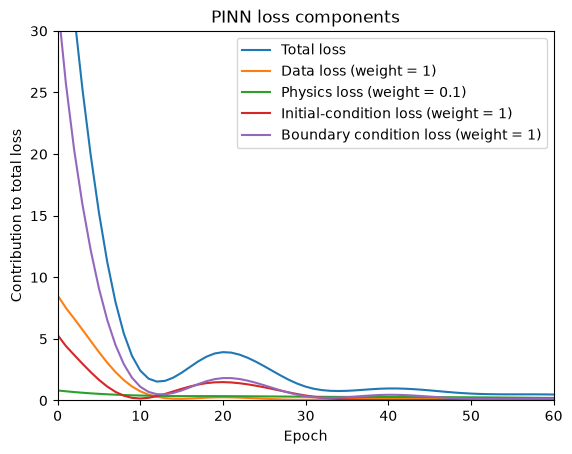

Last recorded total loss: 0.000505
Data contribution:        0.000023
Physics contribution:     0.000387
IC contribution:          0.000037
BC contribution:          0.000058


In [418]:
plt.plot(train_losses_heat, label="Total loss")
plt.plot(data_losses_heat, label="Data loss (weight = 1)")
plt.plot(phys_losses_heat, label="Physics loss (weight = %g)" % lambda_phys)
plt.plot(IC_losses_heat, label="Initial-condition loss (weight = %g)" % lambda_IC)
plt.plot(BC_losses_heat, label="Boundary condition loss (weight = %g)" % lambda_BC)

plt.xlabel("Epoch")
plt.ylabel("Contribution to total loss")
plt.title("PINN loss components")
plt.xlim([0, 60])
plt.ylim([0, 30])
plt.legend()
plt.show()

print("Last recorded total loss: %0.6f" % train_losses_heat[-1])
print("Data contribution:        %0.6f" % data_losses_heat[-1])
print("Physics contribution:     %0.6f" % phys_losses_heat[-1])
print("IC contribution:          %0.6f" % IC_losses_heat[-1])
print("BC contribution:          %0.6f" % BC_losses_heat[-1])

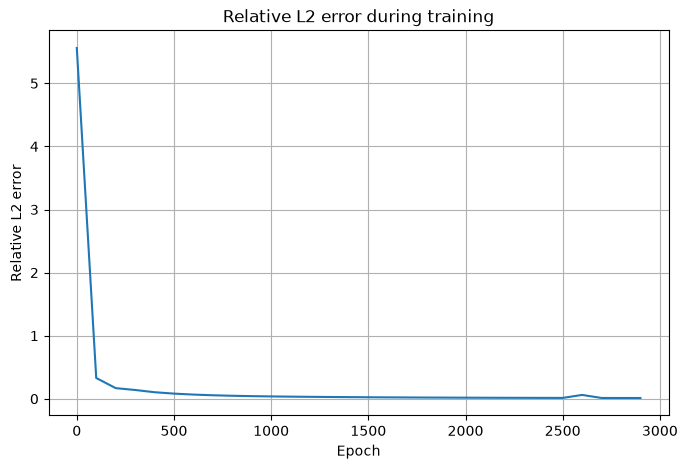

In [419]:
epochs = np.arange(0, num_epochs, 100)

plt.figure(figsize=(8, 5))
plt.plot(epochs, l2_errors)
plt.xlabel("Epoch")
plt.ylabel("Relative L2 error")
plt.title("Relative L2 error during training")
plt.grid()
plt.show()

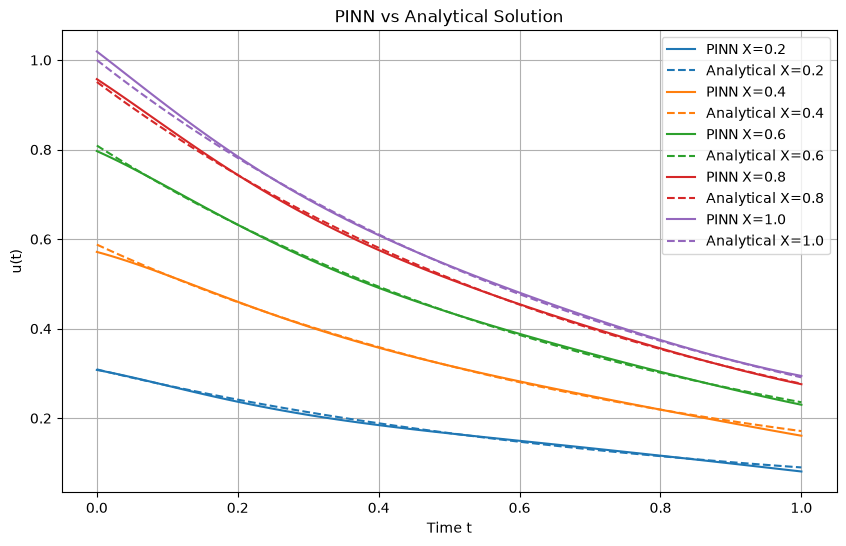

In [420]:

x = np.array([0.2, 0.4, 0.6, 0.8, 1.0])

np.random.seed(42)

def data_generator(n_samples=100, L=2, T=1, alpha=0.5):
    # Create covariates and response variable
    t = np.linspace(0, T, n_samples)
    x = np.ones(100)*0.2
    y = np.sin(np.pi*x/L)*np.exp(-alpha*(np.pi/L)**2*t)

    return t, y

data_test1 = data_generator(n_samples=100)

def data_generator(n_samples=100, L=2, T=1, alpha=0.5):
    # Create covariates and response variable
    t = np.linspace(0, T, n_samples)
    x = np.ones(100)*0.4
    y = np.sin(np.pi*x/L)*np.exp(-alpha*(np.pi/L)**2*t)

    return t, y

data_test2 = data_generator(n_samples=100)


def data_generator(n_samples=100, L=2, T=1, alpha=0.5):
    # Create covariates and response variable
    t = np.linspace(0, T, n_samples)
    x = np.ones(100)*0.6
    y = np.sin(np.pi*x/L)*np.exp(-alpha*(np.pi/L)**2*t)

    return t, y

data_test3 = data_generator(n_samples=100)


def data_generator(n_samples=100, L=2, T=1, alpha=0.5):
    # Create covariates and response variable
    t = np.linspace(0, T, n_samples)
    x = np.ones(100)*0.8
    y = np.sin(np.pi*x/L)*np.exp(-alpha*(np.pi/L)**2*t)

    return t, y

data_test4 = data_generator(n_samples=100)


def data_generator(n_samples=100, L=2, T=1, alpha=0.5):
    # Create covariates and response variable
    t = np.linspace(0, T, n_samples)
    x = np.ones(100)*1.0
    y = np.sin(np.pi*x/L)*np.exp(-alpha*(np.pi/L)**2*t)

    return t, y

data_test5 = data_generator(n_samples=100)


te_target_1 = torch.from_numpy(data_test1[1]).reshape(-1, 1)
te_inputs_1 = torch.stack([torch.from_numpy(data_test1[0]).float(),(torch.from_numpy(np.ones(100)*0.2)).float()], dim=1)

te_target_2 = torch.from_numpy(data_test2[1]).reshape(-1, 1)
te_inputs_2 = torch.stack([torch.from_numpy(data_test2[0]).float(),(torch.from_numpy(np.ones(100)*0.4)).float()], dim=1)

te_target_3 = torch.from_numpy(data_test3[1]).reshape(-1, 1)
te_inputs_3 = torch.stack([torch.from_numpy(data_test3[0]).float(),(torch.from_numpy(np.ones(100)*0.6)).float()], dim=1)

te_target_4 = torch.from_numpy(data_test4[1]).reshape(-1, 1)
te_inputs_4 = torch.stack([torch.from_numpy(data_test4[0]).float(),(torch.from_numpy(np.ones(100)*0.8)).float()], dim=1)

te_target_5 = torch.from_numpy(data_test5[1]).reshape(-1, 1)
te_inputs_5 = torch.stack([torch.from_numpy(data_test5[0]).float(),(torch.from_numpy(np.ones(100)*1.0)).float()], dim=1)


te_output1 = net(te_inputs_1).detach().numpy()
te_output2 = net(te_inputs_2).detach().numpy()
te_output3 = net(te_inputs_3).detach().numpy()
te_output4 = net(te_inputs_4).detach().numpy()
te_output5 = net(te_inputs_5).detach().numpy()

t1= data_test1[0]
t2= data_test2[0]
t3= data_test3[0]
t4= data_test4[0]
t5= data_test5[0]



plt.figure(figsize=(10, 6))

line1, = plt.plot(t1, te_output1, label="PINN X=0.2")
plt.plot(t1, te_target_1, "--", color=line1.get_color(),
         label="Analytical X=0.2")
#plt.scatter(data_test1[0], data_test1[1],
#            color=line1.get_color(), label="Training data X=0.2")

line2, = plt.plot(t2, te_output2, label="PINN X=0.4")
plt.plot(t2, te_target_2, "--", color=line2.get_color(),
         label="Analytical X=0.4")
#plt.scatter(data_test2[0], data_test2[1],
#            color=line2.get_color(), label="Training data X=0.4")

line3, = plt.plot(t3, te_output3, label="PINN X=0.6")
plt.plot(t3, te_target_3, "--", color=line3.get_color(),
         label="Analytical X=0.6")
#plt.scatter(data_test3[0], data_test3[1],
#            color=line3.get_color(), label="Training data X=0.6")

line4, = plt.plot(t4, te_output4, label="PINN X=0.8")
plt.plot(t4, te_target_4, "--", color=line4.get_color(),
         label="Analytical X=0.8")
#plt.scatter(data_test4[0], data_test4[1],
#            color=line4.get_color(), label="Training data X=0.8")

line5, = plt.plot(t5, te_output5, label="PINN X=1.0")
plt.plot(t5, te_target_5, "--", color=line5.get_color(),
         label="Analytical X=1.0")
#plt.scatter(data_test5[0], data_test5[1],
#            color=line5.get_color(), label="Training data X=1.0")

plt.xlabel("Time t")
plt.ylabel("u(t)")
plt.title("PINN vs Analytical Solution")
plt.legend()
plt.grid()
plt.show()


In [421]:
#L2 error

l2_error1 = np.linalg.norm(te_output1 - te_target_1.numpy()) / np.linalg.norm(te_target_1.numpy())
l2_error2 = np.linalg.norm(te_output2 - te_target_2.numpy()) / np.linalg.norm(te_target_2.numpy())
l2_error3 = np.linalg.norm(te_output3 - te_target_3.numpy()) / np.linalg.norm(te_target_3.numpy())
l2_error4 = np.linalg.norm(te_output4 - te_target_4.numpy()) / np.linalg.norm(te_target_4.numpy())
l2_error5 = np.linalg.norm(te_output5 - te_target_5.numpy()) / np.linalg.norm(te_target_5.numpy())

print(f"Relative L2 error at x={0.2}: {l2_error1:.6f}")
print(f"Relative L2 error at x={0.4}: {l2_error2:.6f}")
print(f"Relative L2 error at x={0.6}: {l2_error3:.6f}")
print(f"Relative L2 error at x={0.8}: {l2_error4:.6f}")
print(f"Relative L2 error at x={1.0}: {l2_error5:.6f}")

Relative L2 error at x=0.2: 0.019419
Relative L2 error at x=0.4: 0.010836
Relative L2 error at x=0.6: 0.006097
Relative L2 error at x=0.8: 0.007024
Relative L2 error at x=1.0: 0.010697


In [422]:
#Heat plot

import numpy as np
import matplotlib.pyplot as plt
import torch

# Create a grid of space and time values
x_values = np.linspace(0, L, 100)
t_values = np.linspace(0, 1, 100)

X, TT = np.meshgrid(x_values, t_values)

# Convert grid to PyTorch tensor
test_input = np.column_stack((TT.flatten(), X.flatten()))
test_input = torch.tensor(test_input, dtype=torch.float32)

# Predict using the trained PINN
net.eval()
with torch.no_grad():
    U_pred = net(test_input).cpu().numpy()

# Reshape predictions to match the grid
U_pred = U_pred.reshape(len(t_values), len(x_values))

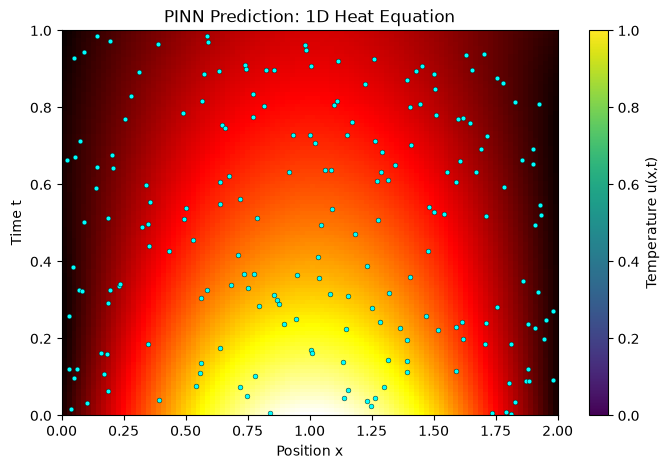

In [423]:
#Pinn solution heatmap

plt.figure(figsize=(8, 5))

plt.imshow(
    U_pred,
    extent=[0, L, 0, 1],
    aspect="auto",
    cmap="hot",
    origin="lower"
)

plt.scatter(
    colloc_input[:, 1].numpy(),
    colloc_input[:, 0].numpy(),
    color="cyan",
    s=12,
    marker="o",
    label="Collocation points",
    edgecolors="black",
    linewidths=0.3
)

plt.colorbar(label="Temperature u(x,t)")
plt.xlabel("Position x")
plt.ylabel("Time t")
plt.title("PINN Prediction: 1D Heat Equation")

plt.show()

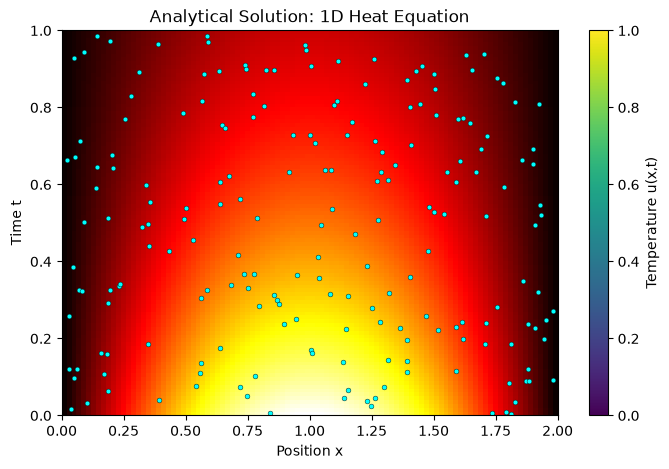

In [424]:
#Analytic heatmap

import matplotlib.pyplot as plt

L = 2
T = 1
alpha = 0.5

# Create space and time values
x = np.linspace(0, L, 100)
t = np.linspace(0, T, 100)

# Create 2D grid
X, TT = np.meshgrid(x, t)

# Calculate analytical solution
U_exact = np.sin(np.pi * X / L) * np.exp(
    -alpha * (np.pi / L)**2 * TT
)

# Plot analytical solution
plt.figure(figsize=(8, 5))

plt.imshow(
    U_exact,
    extent=[0, L, 0, T],
    aspect="auto",
    cmap="hot",
    origin="lower",
    vmin=0,
    vmax=1
)

plt.scatter(
    colloc_input[:, 1].numpy(),
    colloc_input[:, 0].numpy(),
    color="cyan",
    s=12,
    marker="o",
    label="Collocation points",
    edgecolors="black",
    linewidths=0.3
)

plt.colorbar(label="Temperature u(x,t)")
plt.xlabel("Position x")
plt.ylabel("Time t")
plt.title("Analytical Solution: 1D Heat Equation")

plt.show()




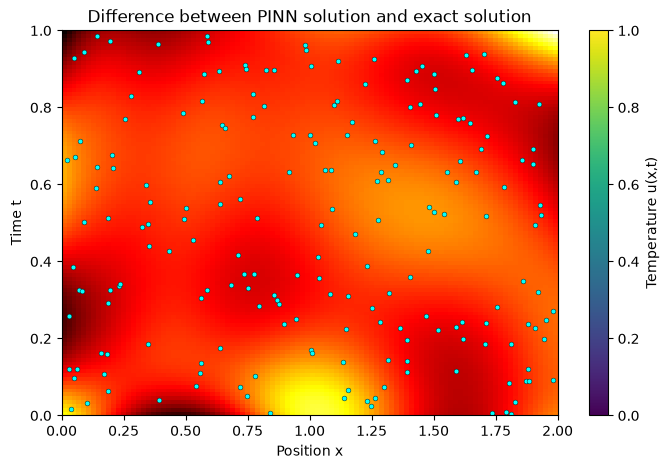

In [425]:
plt.figure(figsize=(8, 5))

plt.imshow(
    U_pred-U_exact,
    extent=[0, L, 0, 1],
    aspect="auto",
    cmap="hot",
    origin="lower"
)

plt.scatter(
    colloc_input[:, 1].numpy(),
    colloc_input[:, 0].numpy(),
    color="cyan",
    s=12,
    marker="o",
    label="Collocation points",
    edgecolors="black",
    linewidths=0.3
)

plt.colorbar(label="Temperature u(x,t)")
plt.xlabel("Position x")
plt.ylabel("Time t")
plt.title("Difference between PINN solution and exact solution")

plt.show()